# ORD Departure Reliability

A look at gate-departure delays at Chicago O’Hare, from January 2023 through May 2026. All tables and charts are already rendered.

**Giang Bui** · [Overview](README.md) · [Data cleaning](ord_data_cleaning.ipynb)

This EDA feeds into a follow-up delay prediction project.

## Introduction

Which departure hours have the highest delay rates? How do patterns change by month, marketing airline network, and destination?

The data comes from [BTS Detailed Statistics Departures](https://www.transtats.bts.gov/ontime/Departures.aspx). It contains 1,131,245 ORD records from 2023-01-01 to 2026-05-31; cleaning leaves 1,109,123 departures for analysis.

Marketing networks include regional partners. Destination comparisons describe flights leaving ORD. A separate section looks at reported arrival-delay causes for these flights.

## Load the data

Install `pip install -r requirements.txt`, then open this notebook from the repository folder. Set `ORD_DATA_DIR` to your local `cleaned_data/` folder; the default is `../cleaned_data`.

The [cleaning notebook](ord_data_cleaning.ipynb) explains the BTS schema fixes and exclusions. Flight records stay outside this repository.

In [1]:
from pathlib import Path
import os

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 2)
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'figure.dpi': 110})
# Read the file produced by the cleaning notebook.
data_dir = Path(os.environ.get('ORD_DATA_DIR', '../cleaned_data'))
flights = pd.read_parquet(data_dir / 'ord_departures_2023_2026_analysis_ready.parquet')
# Calendar columns for the charts below.
flights['YEAR'] = flights.FLIGHT_DATE.dt.year
flights['MONTH'] = flights.FLIGHT_DATE.dt.month

# Read the small report describing how the data was cleaned.
with (data_dir / 'cleaning_summary.json').open() as report_file:
    cleaning_summary = json.load(report_file)

print(f'{len(flights):,} eligible ORD departures loaded and validated')
delay = flights['DEP_DELAY']
headline_metrics = {'analysis_ready_rows': len(flights), 'first_date': str(flights['FLIGHT_DATE'].min().date()), 'last_date': str(flights['FLIGHT_DATE'].max().date()), 'departure_delay_mean_minutes': float(delay.mean()), 'departure_delay_median_minutes': float(delay.median()), 'departure_delay_p90_minutes': float(delay.quantile(0.9)), 'departure_delay_p99_minutes': float(delay.quantile(0.99)), 'departure_delayed15_rows': int(delay.ge(15).sum()), 'departure_delayed15_pct': float(delay.ge(15).mean() * 100), 'positive_departure_delay_minutes': float(delay.clip(lower=0).sum()), 'taxi_out_median_minutes': float(flights['TAXI_OUT'].median())}
display(pd.Series(headline_metrics, name='headline metrics').to_frame())


1,109,123 eligible ORD departures loaded and validated


,headline metrics
analysis_ready_rows,1109123
first_date,2023-01-01
last_date,2026-05-31
departure_delay_mean_minutes,16.06
departure_delay_median_minutes,-2.0
departure_delay_p90_minutes,56.0
departure_delay_p99_minutes,233.0
departure_delayed15_rows,254754
departure_delayed15_pct,22.97
positive_departure_delay_minutes,20953173.0


## Understanding the cleaned data

In [2]:
# Focus the missing-value check on the columns used in this analysis.
analysis_columns = ['FLIGHT_DATE', 'MARKETING_CARRIER', 'OPERATING_CARRIER', 'ORIGIN',
    'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'SCHEDULED_DEP_HOUR', 'DEP_DELAY',
    'DEP_DELAY_15', 'POSITIVE_DEP_DELAY_MINUTES', 'TAXI_OUT', 'CARRIER_DELAY',
    'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']
analysis_data = flights[analysis_columns]

schema = pd.DataFrame()
schema['dtype'] = analysis_data.dtypes.astype(str)
schema['missing_rows'] = analysis_data.isna().sum()
schema['missing_pct'] = analysis_data.isna().mean() * 100
schema['unique_values'] = analysis_data.nunique()
display(schema)
print('Origins:', flights['ORIGIN'].unique().tolist())
print('Unique source rows:', flights['SOURCE_ROW_ID'].nunique())


Origins: ['ORD']
Unique source rows: 1109123


,dtype,missing_rows,missing_pct,unique_values
FLIGHT_DATE,datetime64[us],0,0.0,1247
MARKETING_CARRIER,string,0,0.0,8
OPERATING_CARRIER,string,0,0.0,17
ORIGIN,string,0,0.0,1
DEST,string,0,0.0,195
CRS_DEP_TIME,Int64,0,0.0,1139
DEP_TIME,Int64,0,0.0,1373
SCHEDULED_DEP_HOUR,Int64,0,0.0,20
DEP_DELAY,Float64,0,0.0,1312
DEP_DELAY_15,boolean,0,0.0,2


### Cleaning checks

The cleaned master keeps source values and quality flags. The analysis-ready file excludes cancelled or diverted flights, ambiguous duplicates, unknown statuses, and invalid measurements. No further rows are removed here.

In [3]:
display(pd.Series(cleaning_summary, name='cleaning audit').to_frame())
exclusion_report = pd.read_csv(data_dir / 'exclusion_rules.csv')
display(exclusion_report)
print('Exclusion categories overlap. They must not be summed as distinct excluded records.')
assert len(flights) == cleaning_summary['analysis_ready_rows']
assert flights['ELIGIBLE_DEPARTURE_ANALYSIS'].all()
assert flights['SOURCE_ROW_ID'].is_unique
assert (flights['ORIGIN'] == 'ORD').all()
assert flights['DEP_DELAY'].notna().all()
assert flights['CANCELLATION_CODE'].isna().all()
print('Cleaned-input checks passed.')


Exclusion categories overlap. They must not be summed as distinct excluded records.
Cleaned-input checks passed.


,cleaning audit
input_file,ord_departures_2023_2026.parquet
input_sha256,49397121c3985ab0fdc71eb1ec61d6f0f5e72a4ab31abe...
raw_rows,1131245
exact_duplicates_removed,0
cleaned_rows,1131245
analysis_ready_rows,1109123
excluded_rows,22122
first_date,2023-01-01
last_date,2026-05-31
source_url,https://www.transtats.bts.gov/ontime/Departure...


,rule,rows
0,invalid_date,0
1,non_ord_origin,0
2,source_month_mismatch,0
3,missing_key,0
4,repeated_key,68
5,source_duplicate_marker,96
6,unknown_duplicate_marker,0
7,not_verified_non_cancelled,19039
8,not_verified_non_diverted,3049
9,cancellation_code_present,19038


## Measurement rules

- A delayed departure leaves the gate at least 15 minutes behind schedule.
- Signed delays keep early departures as negative values; positive delay minutes count late minutes only.
- Rates use the cleaned departure sample. Calendar groups use service date and corrected scheduled local time.
- No delays are filled in or trimmed. Arrival-delay causes are summarized separately.

In [4]:
flights['Date'] = flights['FLIGHT_DATE']
flights['Year'] = flights['YEAR']
flights['Month'] = flights['MONTH']
flights['MonthStart'] = flights['Date'].dt.to_period('M').dt.to_timestamp()
flights['Weekday'] = flights['Date'].dt.day_name()
flights['ScheduledDepHour'] = flights['SCHEDULED_DEP_HOUR']
flights['DepDelayed15'] = flights['DEP_DELAY_15']
flights['PositiveDepDelay'] = flights['POSITIVE_DEP_DELAY_MINUTES']
assert (flights['DepDelayed15'] == (flights['DEP_DELAY'] >= 15)).all()
assert len(flights) == cleaning_summary['analysis_ready_rows']
print(f'All {len(flights):,} cleaned departure observations retained for analysis.')


All 1,109,123 cleaned departure observations retained for analysis.


First date: 2023-01-01 00:00:00
Last date: 2026-05-31 00:00:00


,eligible_departures,observed_days,calendar_days,all_calendar_dates_present
MonthStart,,,,
2023-01-01,22745,31,31,True
2023-02-01,21685,28,28,True
2023-03-01,24498,31,31,True
2023-04-01,23691,30,30,True
2023-05-01,24944,31,31,True
2023-06-01,24385,30,30,True
2023-07-01,25121,31,31,True
2023-08-01,26268,31,31,True
2023-09-01,25122,30,30,True


,eligible_departures,months,first_date,last_date
Year,,,,
2023,290805,12,2023-01-01,2023-12-31
2024,313126,12,2024-01-01,2024-12-31
2025,350071,12,2025-01-01,2025-12-31
2026,155121,5,2026-01-01,2026-05-31


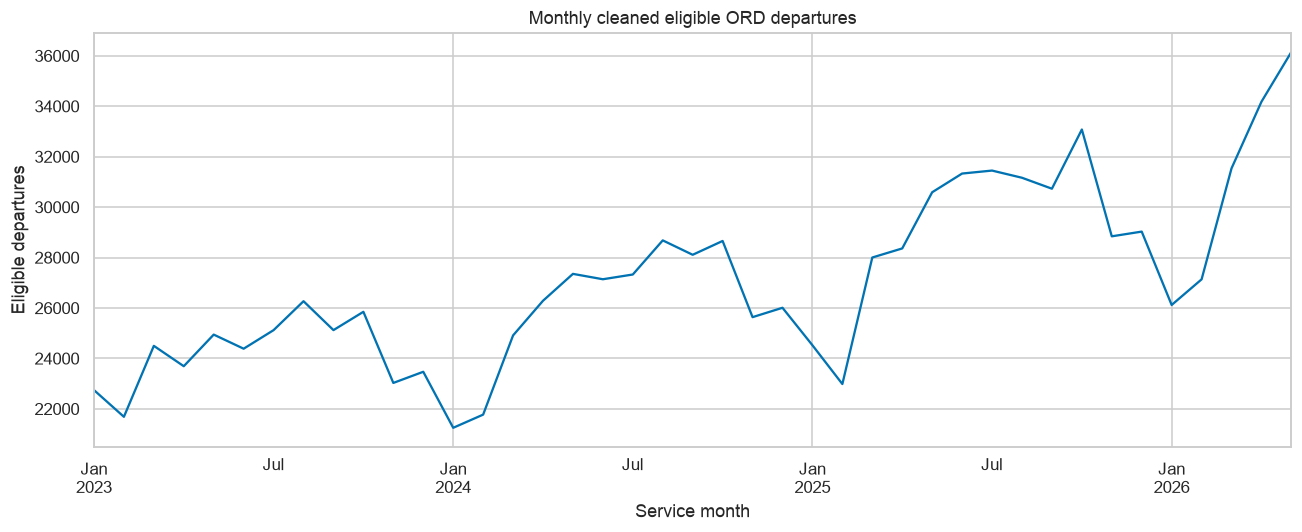

In [5]:
# Monthly counts show the amount of data available for each month.
monthly_groups = flights.groupby('MonthStart')
coverage = pd.DataFrame()
coverage['eligible_departures'] = monthly_groups['Date'].size()
coverage['observed_days'] = monthly_groups['Date'].nunique()
coverage['calendar_days'] = coverage.index.days_in_month
coverage['all_calendar_dates_present'] = coverage['observed_days'] == coverage['calendar_days']
print('First date:', flights['Date'].min())
print('Last date:', flights['Date'].max())
display(coverage)

# Keep partial years visible instead of treating them as complete years.
yearly_groups = flights.groupby('Year')
yearly_coverage = pd.DataFrame()
yearly_coverage['eligible_departures'] = yearly_groups['Date'].size()
yearly_coverage['months'] = yearly_groups['Month'].nunique()
yearly_coverage['first_date'] = yearly_groups['Date'].min()
yearly_coverage['last_date'] = yearly_groups['Date'].max()
display(yearly_coverage)

coverage['eligible_departures'].plot(title='Monthly cleaned eligible ORD departures')
plt.ylabel('Eligible departures')
plt.xlabel('Service month')
plt.tight_layout()
plt.show()


2026 ends on May 31. The year comparison below uses January–May for every year.

## Departure delays

### Distribution and severity

Skewness: 9.10; excess kurtosis: 140.72
15+ minute delay rate: 22.97% (n=1,109,123)


,signed departure delay (min)
count,1109123.0
mean,16.06
std,60.43
min,-42.0
1%,-12.0
50%,-2.0
90%,56.0
95%,100.0
99%,233.0
max,2446.0


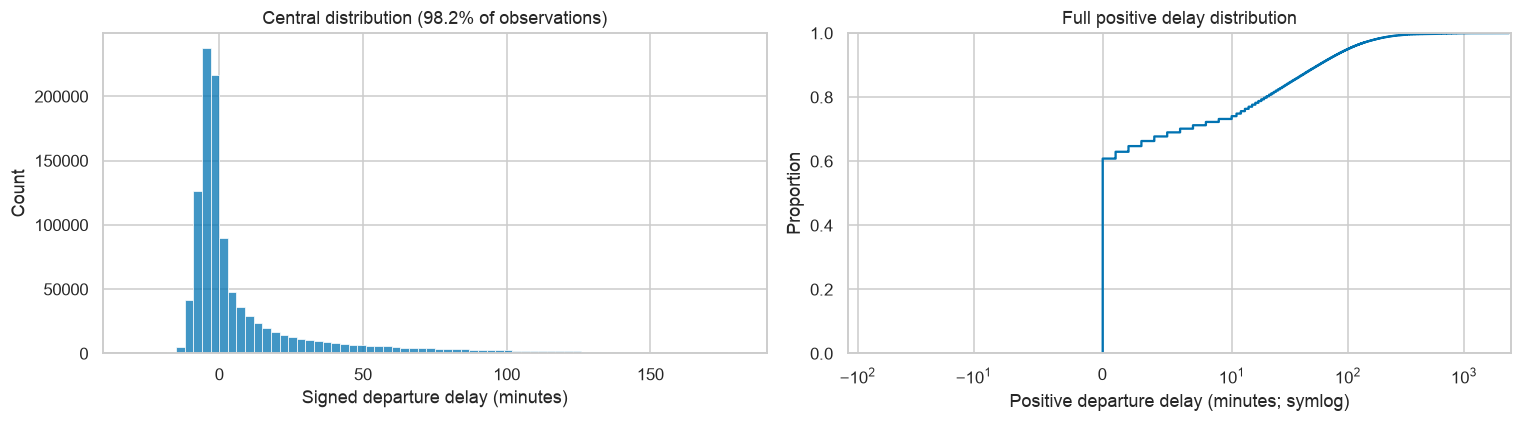

In [6]:
display(flights['DEP_DELAY'].describe(percentiles=[.01, .5, .9, .95, .99]).to_frame('signed departure delay (min)'))
print(f"Skewness: {flights.DEP_DELAY.skew():.2f}; excess kurtosis: {flights.DEP_DELAY.kurt():.2f}")
print(f"15+ minute delay rate: {flights.DepDelayed15.mean():.2%} (n={len(flights):,})")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
window = flights['DEP_DELAY'].between(-30, 180)
sns.histplot(flights.loc[window, 'DEP_DELAY'], bins=70, ax=axes[0])
axes[0].set(title=f'Central distribution ({window.mean():.1%} of observations)', xlabel='Signed departure delay (minutes)')
sns.ecdfplot(data=flights, x='PositiveDepDelay', ax=axes[1])
axes[1].set_xscale('symlog', linthresh=10)
axes[1].set(title='Full positive delay distribution', xlabel='Positive departure delay (minutes; symlog)')
plt.tight_layout()
plt.show()


,flights,share_pct
DEP_DELAY,,
Early (<0),628114,56.63
0–14 min,226255,20.40
15–59 min,150540,13.57
60–179 min,84256,7.60
180+ min,19958,1.80


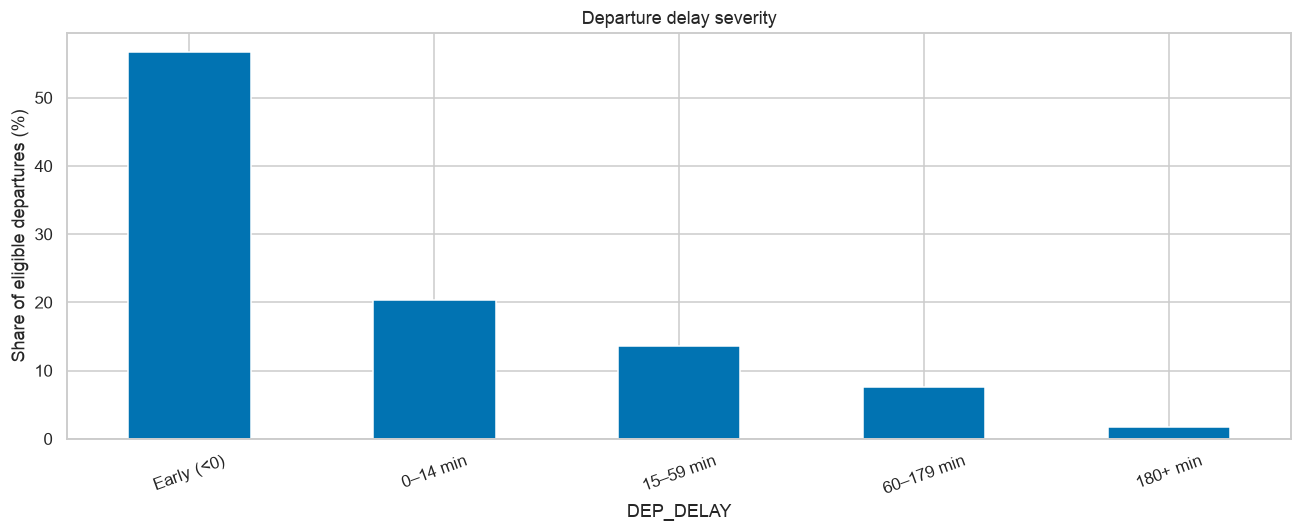

In [7]:
severity = pd.cut(flights['DEP_DELAY'], bins=[-np.inf, 0, 15, 60, 180, np.inf], right=False,
                  labels=['Early (<0)', '0–14 min', '15–59 min', '60–179 min', '180+ min'])
severity_table = severity.value_counts(sort=False).to_frame('flights')
severity_table['share_pct'] = severity_table['flights'] / len(flights) * 100
display(severity_table)
severity_table['share_pct'].plot.bar(title='Departure delay severity', rot=20)
plt.ylabel('Share of eligible departures (%)')
plt.tight_layout()
plt.show()


### Scheduled hour and weekday

Group by scheduled departure hour and show the flight count alongside each delay rate.

,flights,mean_minutes,median_minutes,p90_minutes,delayed15_pct
ScheduledDepHour,,,,,
0,364,21.68,3.0,52.7,34.89
5,10128,6.11,-4.0,14.0,9.87
6,28418,5.29,-4.0,14.0,9.91
7,76716,4.68,-4.0,18.0,10.99
8,99884,8.61,-3.0,29.0,15.15
9,84566,10.04,-3.0,38.0,17.59
10,84330,11.81,-3.0,46.0,19.18
11,46003,13.71,-3.0,56.0,22.15
12,55215,13.09,-2.0,47.0,20.8


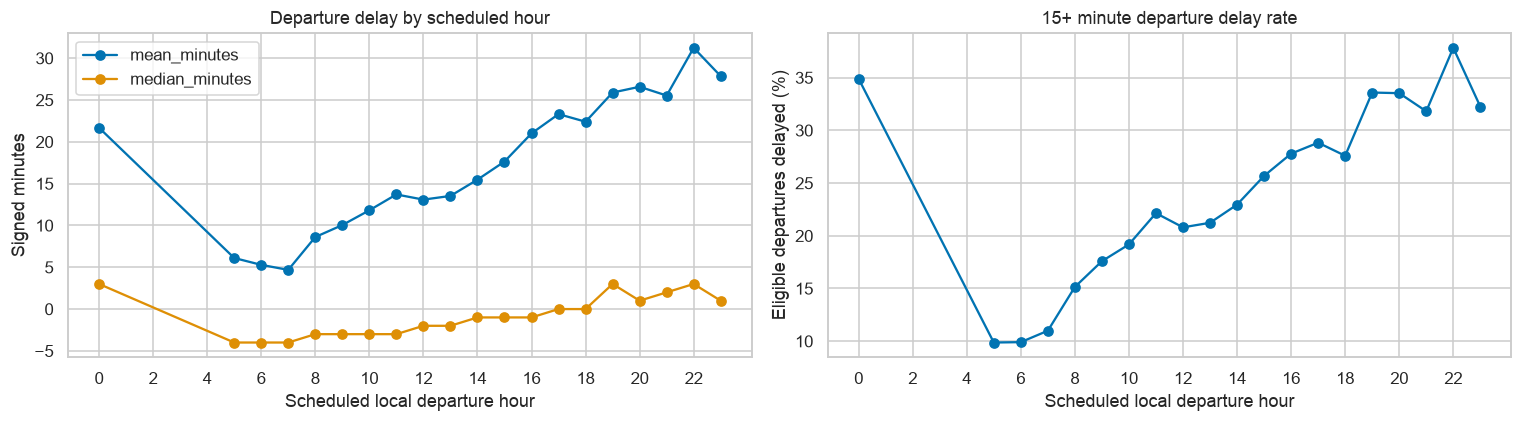

,flights,mean_minutes,median_minutes,p90_minutes,delayed15_pct
Weekday,,,,,
Monday,163288,16.89,-2.0,58.3,23.32
Tuesday,152977,13.95,-2.0,49.0,20.17
Wednesday,155471,14.67,-2.0,53.0,21.37
Thursday,163542,15.84,-1.0,55.0,23.46
Friday,164257,17.38,-1.0,59.0,24.85
Saturday,146853,14.53,-2.0,51.0,21.89
Sunday,162735,18.83,-1.0,64.0,25.36


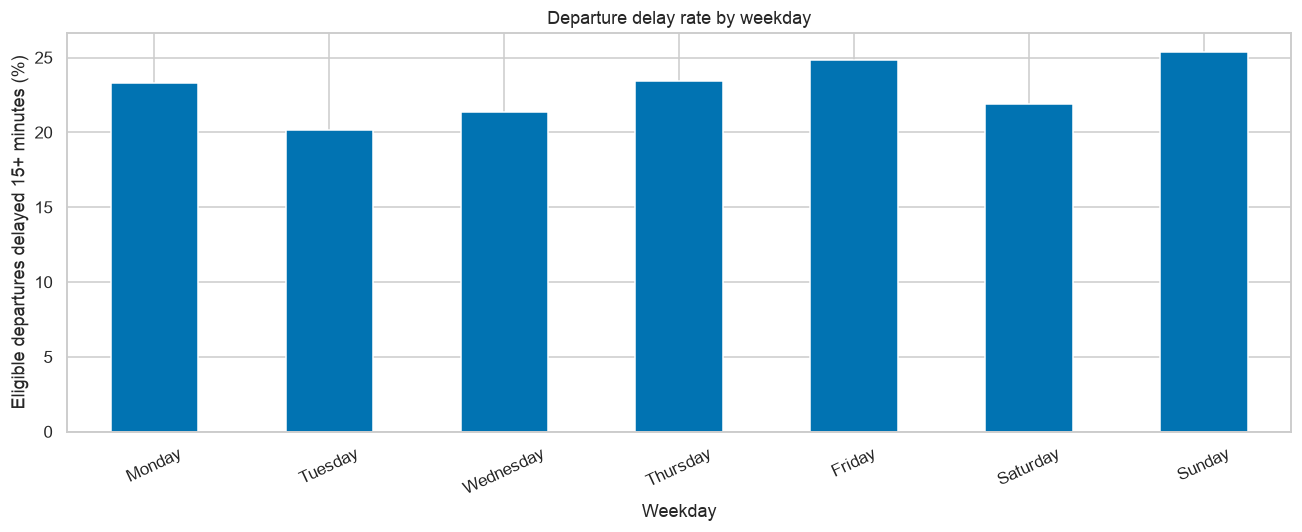

In [8]:
# Group flights by ScheduledDepHour, then calculate one measure at a time.
grouped = flights.groupby('ScheduledDepHour', observed=True)
hourly = pd.DataFrame()
hourly['flights'] = grouped['DEP_DELAY'].count()
hourly['mean_minutes'] = grouped['DEP_DELAY'].mean()
hourly['median_minutes'] = grouped['DEP_DELAY'].median()
hourly['p90_minutes'] = grouped['DEP_DELAY'].quantile(0.90)
# The mean of a True/False column is the fraction that is True.
hourly['delayed15_pct'] = grouped['DepDelayed15'].mean() * 100

display(hourly)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hourly[['mean_minutes', 'median_minutes']].plot(ax=axes[0], marker='o', title='Departure delay by scheduled hour')
hourly['delayed15_pct'].plot(ax=axes[1], marker='o', title='15+ minute departure delay rate')
axes[0].set_xlabel('Scheduled local departure hour')
axes[0].set_xticks(range(0, 24, 2))
axes[1].set_xlabel('Scheduled local departure hour')
axes[1].set_xticks(range(0, 24, 2))
axes[0].set_ylabel('Signed minutes')
axes[1].set_ylabel('Eligible departures delayed (%)')
plt.tight_layout()
plt.show()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# Group flights by Weekday, then calculate one measure at a time.
grouped = flights.groupby('Weekday', observed=True)
weekday = pd.DataFrame()
weekday['flights'] = grouped['DEP_DELAY'].count()
weekday['mean_minutes'] = grouped['DEP_DELAY'].mean()
weekday['median_minutes'] = grouped['DEP_DELAY'].median()
weekday['p90_minutes'] = grouped['DEP_DELAY'].quantile(0.90)
# The mean of a True/False column is the fraction that is True.
weekday['delayed15_pct'] = grouped['DepDelayed15'].mean() * 100
weekday = weekday.reindex(weekday_order)
display(weekday)
weekday['delayed15_pct'].plot.bar(rot=25, title='Departure delay rate by weekday')
plt.ylabel('Eligible departures delayed 15+ minutes (%)')
plt.tight_layout()
plt.show()


### Monthly trends and comparable year windows

Months represented in every year: [1, 2, 3, 4, 5]
Aligned month windows still differ in routes, carriers, schedules, and operating conditions.


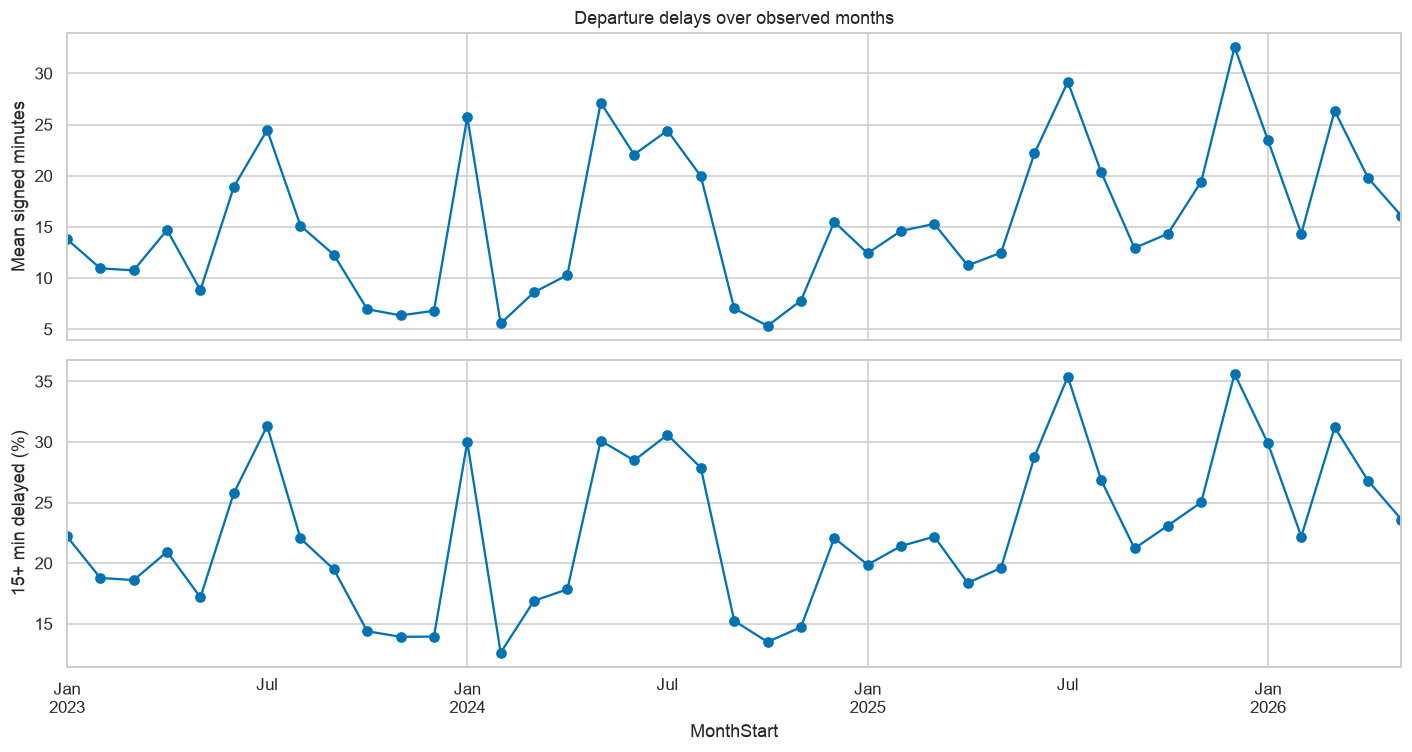

,flights,mean_minutes,median_minutes,p90_minutes,delayed15_pct
Year,,,,,
2023,117563,11.76,-2.0,42.0,19.5
2024,121570,15.59,-2.0,54.0,21.59
2025,134456,13.15,-2.0,47.0,20.24
2026,155121,19.92,-1.0,68.0,26.67


In [9]:
# Group flights by MonthStart, then calculate one measure at a time.
grouped = flights.groupby('MonthStart', observed=True)
monthly_dep = pd.DataFrame()
monthly_dep['flights'] = grouped['DEP_DELAY'].count()
monthly_dep['mean_minutes'] = grouped['DEP_DELAY'].mean()
monthly_dep['median_minutes'] = grouped['DEP_DELAY'].median()
monthly_dep['p90_minutes'] = grouped['DEP_DELAY'].quantile(0.90)
# The mean of a True/False column is the fraction that is True.
monthly_dep['delayed15_pct'] = grouped['DepDelayed15'].mean() * 100

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
monthly_dep['mean_minutes'].plot(ax=axes[0], marker='o', title='Departure delays over observed months')
monthly_dep['delayed15_pct'].plot(ax=axes[1], marker='o')
axes[0].set_ylabel('Mean signed minutes')
axes[1].set_ylabel('15+ min delayed (%)')
plt.tight_layout()
plt.show()
# Find months that appear in every year (January–May in this file).
year_month_pairs = flights[['Year', 'Month']].drop_duplicates()
years_per_month = year_month_pairs.groupby('Month')['Year'].count()
number_of_years = flights['Year'].nunique()
common_months = years_per_month[years_per_month == number_of_years].index.tolist()
print('Months represented in every year:', common_months)

# Compare years using only that shared month window.
common_data = flights[flights['Month'].isin(common_months)]
# Group flights by Year, then calculate one measure at a time.
grouped = common_data.groupby('Year', observed=True)
common_years = pd.DataFrame()
common_years['flights'] = grouped['DEP_DELAY'].count()
common_years['mean_minutes'] = grouped['DEP_DELAY'].mean()
common_years['median_minutes'] = grouped['DEP_DELAY'].median()
common_years['p90_minutes'] = grouped['DEP_DELAY'].quantile(0.90)
# The mean of a True/False column is the fraction that is True.
common_years['delayed15_pct'] = grouped['DepDelayed15'].mean() * 100
display(common_years)
print('Aligned month windows still differ in routes, carriers, schedules, and operating conditions.')


### Marketing airline networks

Compare flight volume and delay rate side by side. Networks serve different routes and departure hours.

,flights,mean_minutes,median_minutes,p90_minutes,delayed15_pct
MARKETING_CARRIER,,,,,
UA,566257,14.61,-2.0,53.0,21.41
AA,427168,17.4,-2.0,58.0,24.38
DL,45881,17.05,-2.0,54.0,21.4
NK,24075,21.71,0.0,73.0,30.69
WN,22483,13.79,0.0,44.0,24.67
AS,10805,14.37,0.0,47.0,26.82
F9,8813,30.64,0.0,91.0,32.25
B6,3641,19.17,-5.0,65.0,24.14


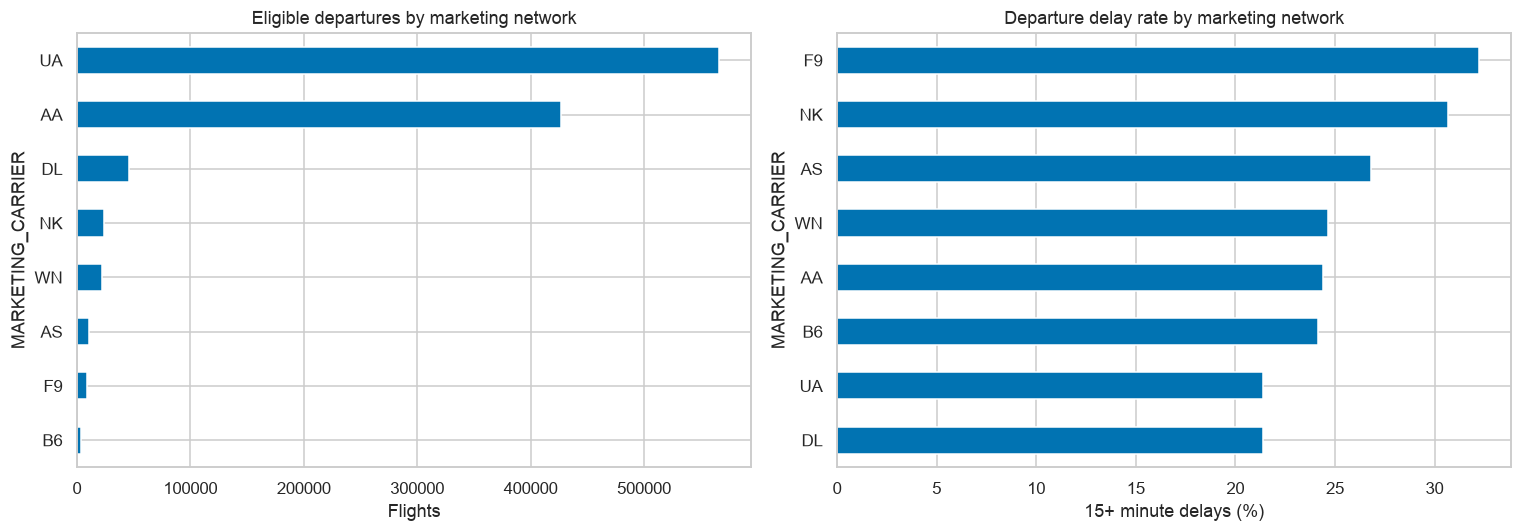

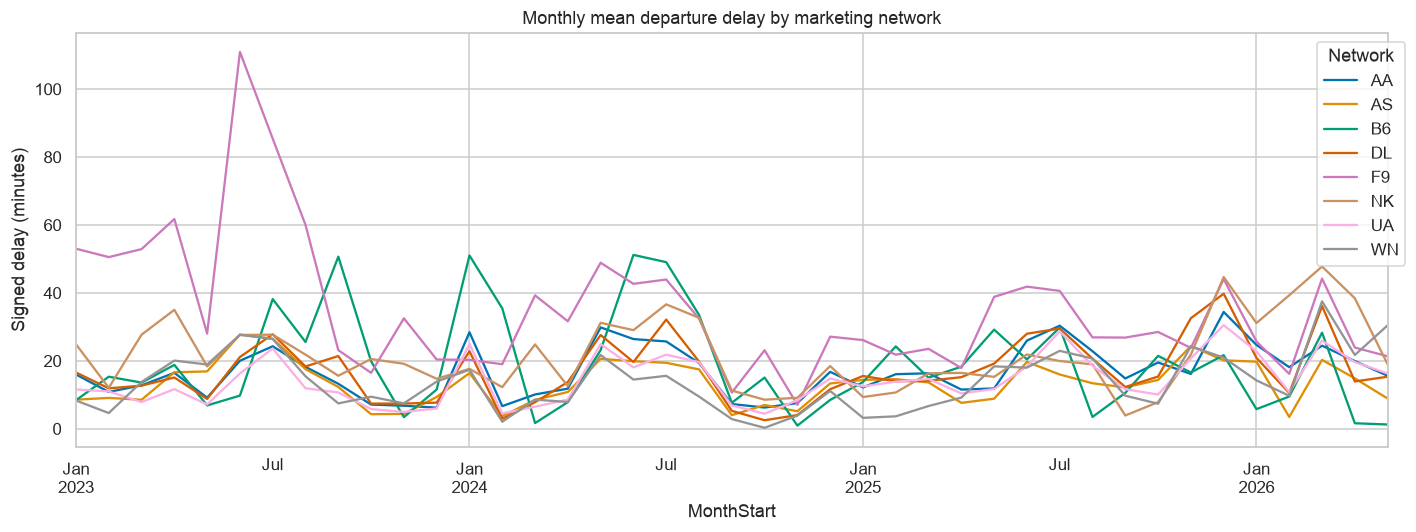

In [10]:
# Group flights by MARKETING_CARRIER, then calculate one measure at a time.
grouped = flights.groupby('MARKETING_CARRIER', observed=True)
carrier_dep = pd.DataFrame()
carrier_dep['flights'] = grouped['DEP_DELAY'].count()
carrier_dep['mean_minutes'] = grouped['DEP_DELAY'].mean()
carrier_dep['median_minutes'] = grouped['DEP_DELAY'].median()
carrier_dep['p90_minutes'] = grouped['DEP_DELAY'].quantile(0.90)
# The mean of a True/False column is the fraction that is True.
carrier_dep['delayed15_pct'] = grouped['DepDelayed15'].mean() * 100
carrier_dep = carrier_dep.sort_values('flights', ascending=False)
display(carrier_dep)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
carrier_dep['flights'].sort_values().plot.barh(ax=axes[0], title='Eligible departures by marketing network')
carrier_dep['delayed15_pct'].sort_values().plot.barh(ax=axes[1], title='Departure delay rate by marketing network')
axes[0].set_xlabel('Flights')
axes[1].set_xlabel('15+ minute delays (%)')
plt.tight_layout()
plt.show()
carrier_month = flights.groupby(['MonthStart', 'MARKETING_CARRIER'])['DEP_DELAY'].mean().unstack()
carrier_month.plot(figsize=(13, 5), title='Monthly mean departure delay by marketing network')
plt.ylabel('Signed delay (minutes)')
plt.legend(title='Network', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


### Destinations

Show the busiest routes and rank mean delays for destinations with at least 1,000 departures.

,flights,mean_minutes,median_minutes,p90_minutes,delayed15_pct,delayed_flights,positive_delay_minutes
DEST,,,,,,,
LGA,35965,17.19,-2.0,63.0,23.8,8560,733885.0
BOS,22978,16.99,-2.0,63.0,25.03,5752,462414.0
LAX,22777,16.9,0.0,53.0,23.95,5456,432606.0
DCA,21586,16.67,-2.0,54.0,22.38,4832,427165.0
DFW,21336,20.39,-1.0,63.0,25.29,5395,482904.0
DEN,21163,15.62,0.0,50.0,23.1,4889,376878.0
ATL,20241,17.72,-1.0,53.0,23.35,4726,406202.0
MSP,20075,16.74,-1.0,56.0,23.67,4751,390237.0
PHX,19629,15.93,-1.0,47.0,22.69,4454,358227.0


,flights,mean_minutes,median_minutes,p90_minutes,delayed15_pct,delayed_flights,positive_delay_minutes
DEST,,,,,,,
JST,1181,38.66,-2.0,76.0,29.81,352,50329.0
SUX,1193,30.79,-1.0,80.0,27.83,332,40329.0
CMX,2371,29.81,-2.0,85.0,28.43,674,78615.0
ASE,3087,26.89,0.0,88.0,30.55,943,90643.0
HSV,3793,25.78,-2.0,87.0,29.13,1105,109663.0
RNO,1038,25.59,6.0,80.0,36.9,383,27821.0
MQT,1933,23.57,-2.0,56.8,23.18,448,50804.0
CAK,4395,23.47,-2.0,87.6,28.03,1232,117045.0
DAY,9210,23.05,-2.0,76.0,24.41,2248,241554.0


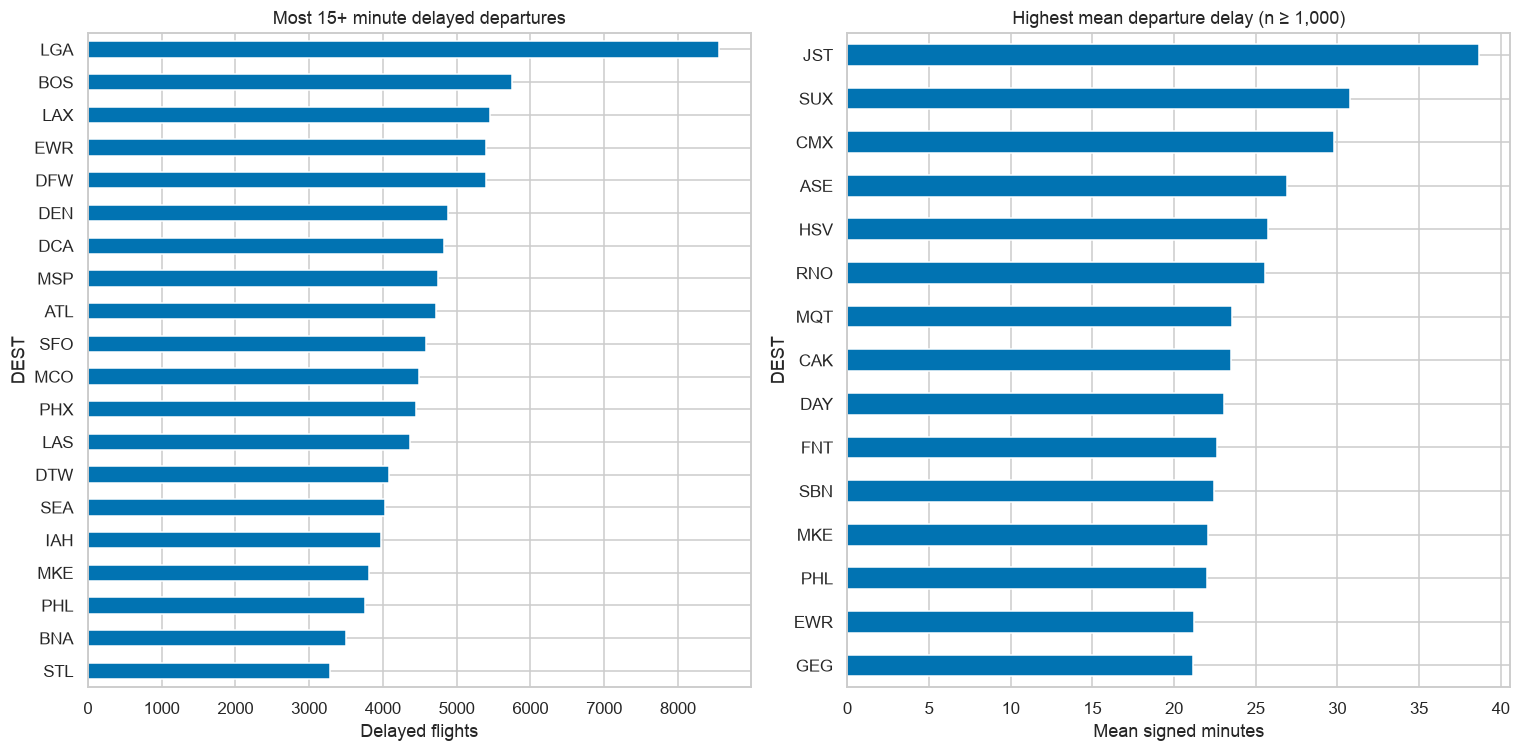

In [11]:
MIN_ROUTE_FLIGHTS = 1000
# Group flights by DEST, then calculate one measure at a time.
grouped = flights.groupby('DEST', observed=True)
routes = pd.DataFrame()
routes['flights'] = grouped['DEP_DELAY'].count()
routes['mean_minutes'] = grouped['DEP_DELAY'].mean()
routes['median_minutes'] = grouped['DEP_DELAY'].median()
routes['p90_minutes'] = grouped['DEP_DELAY'].quantile(0.90)
# The mean of a True/False column is the fraction that is True.
routes['delayed15_pct'] = grouped['DepDelayed15'].mean() * 100

routes['delayed_flights'] = flights.groupby('DEST')['DepDelayed15'].sum()
routes['positive_delay_minutes'] = flights.groupby('DEST')['PositiveDepDelay'].sum()
display(routes.sort_values('flights', ascending=False).head(20))
# First remove small routes, then rank the remaining routes.
large_routes = routes[routes['flights'] >= MIN_ROUTE_FLIGHTS]
route_rank = large_routes.sort_values('mean_minutes', ascending=False)
display(route_rank.head(15))
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
top_delayed_routes = routes.nlargest(20, 'delayed_flights')
top_delayed_routes = top_delayed_routes.sort_values('delayed_flights')
top_delayed_routes['delayed_flights'].plot.barh(ax=axes[0], title='Most 15+ minute delayed departures')
top_average_routes = route_rank.head(15).sort_values('mean_minutes')
top_average_routes['mean_minutes'].plot.barh(ax=axes[1], title=f'Highest mean departure delay (n ≥ {MIN_ROUTE_FLIGHTS:,})')
axes[0].set_xlabel('Delayed flights')
axes[1].set_xlabel('Mean signed minutes')
plt.tight_layout()
plt.show()


## ORD departure patterns

### Seasons and departure hours

Compare months within each year, then weekdays by scheduled hour. Heatmap cells with fewer than 100 flights are left blank.

Month/year rates use eligible departures; blank cells are unobserved or below the stated minimum.


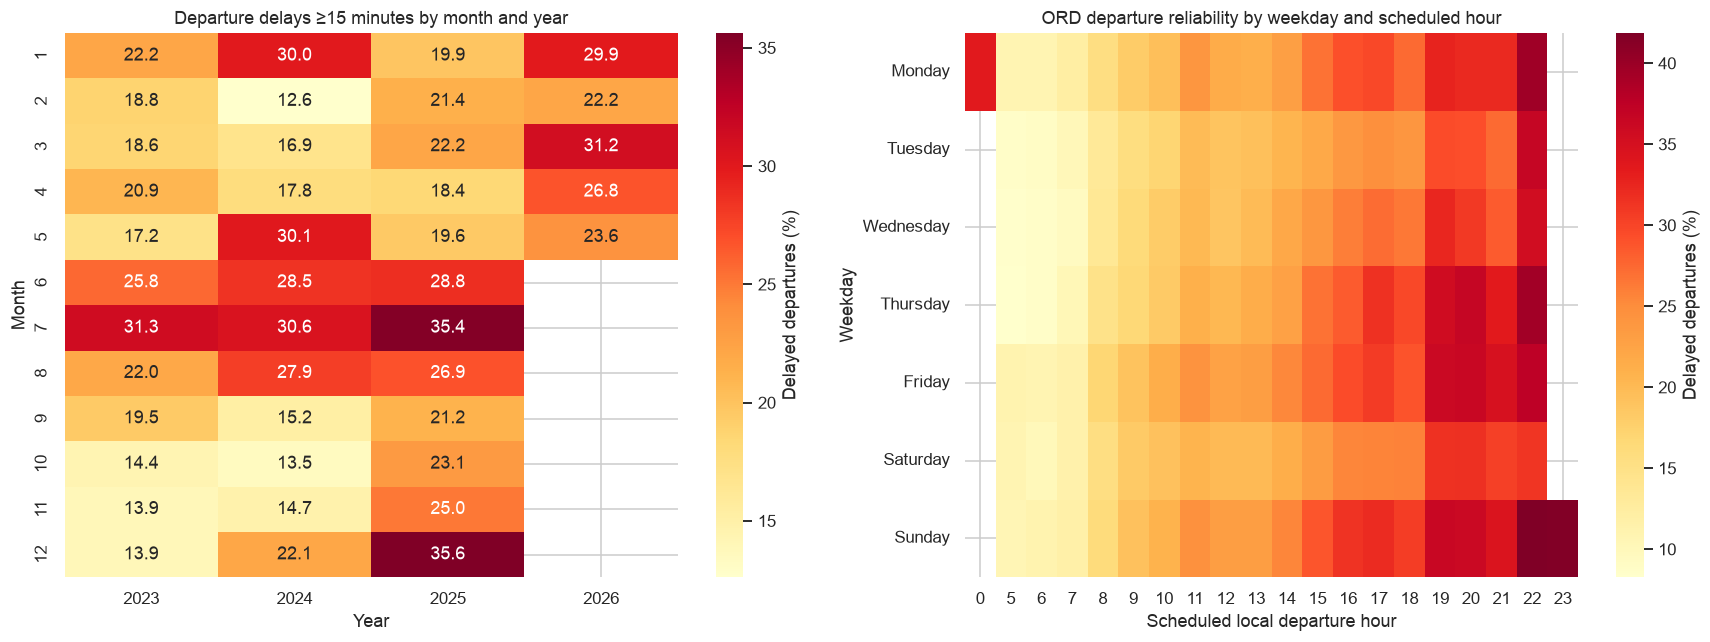

In [12]:
# A pivot table places months in rows and years in columns.
season = flights.pivot_table(index='Month', columns='Year', values='DepDelayed15', aggfunc='mean')
season = season * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(season.astype(float), annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[0], cbar_kws={'label': 'Delayed departures (%)'})
axes[0].set_title('Departure delays ≥15 minutes by month and year')
# Make a second grid with weekdays in rows and scheduled hours in columns.
bank_rate = flights.pivot_table(index='Weekday', columns='ScheduledDepHour', values='DepDelayed15', aggfunc='mean')
bank_rate = bank_rate * 100
bank_rate = bank_rate.reindex(weekday_order)
bank_count = flights.pivot_table(index='Weekday', columns='ScheduledDepHour', values='DEP_DELAY', aggfunc='size')
bank_count = bank_count.reindex(weekday_order)

# Hide rates based on fewer than 100 flights; keep the full table for checking.
visible_bank_rate = bank_rate[bank_count >= 100]
sns.heatmap(visible_bank_rate.astype(float), cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Delayed departures (%)'})
axes[1].set(title='ORD departure reliability by weekday and scheduled hour', xlabel='Scheduled local departure hour', ylabel='Weekday')
plt.tight_layout()
plt.show()
print('Month/year rates use eligible departures; blank cells are unobserved or below the stated minimum.')


### Delay burden

Positive delay minutes count late minutes without subtracting early departures. Compare each network’s share of flights with its share of those minutes.

,flights,positive_delay_minutes,severe_delays,flight_share_pct,delay_minute_share_pct,severe_delay_pct
MARKETING_CARRIER,,,,,,
UA,566257,9897445.0,50985,51.05,47.24,9.0
AA,427168,8606149.0,41871,38.51,41.07,9.8
DL,45881,935538.0,4243,4.14,4.46,9.25
NK,24075,585359.0,2976,2.17,2.79,12.36
WN,22483,354642.0,1604,2.03,1.69,7.13
F9,8813,296846.0,1310,0.79,1.42,14.86
AS,10805,186501.0,826,0.97,0.89,7.64
B6,3641,90693.0,399,0.33,0.43,10.96


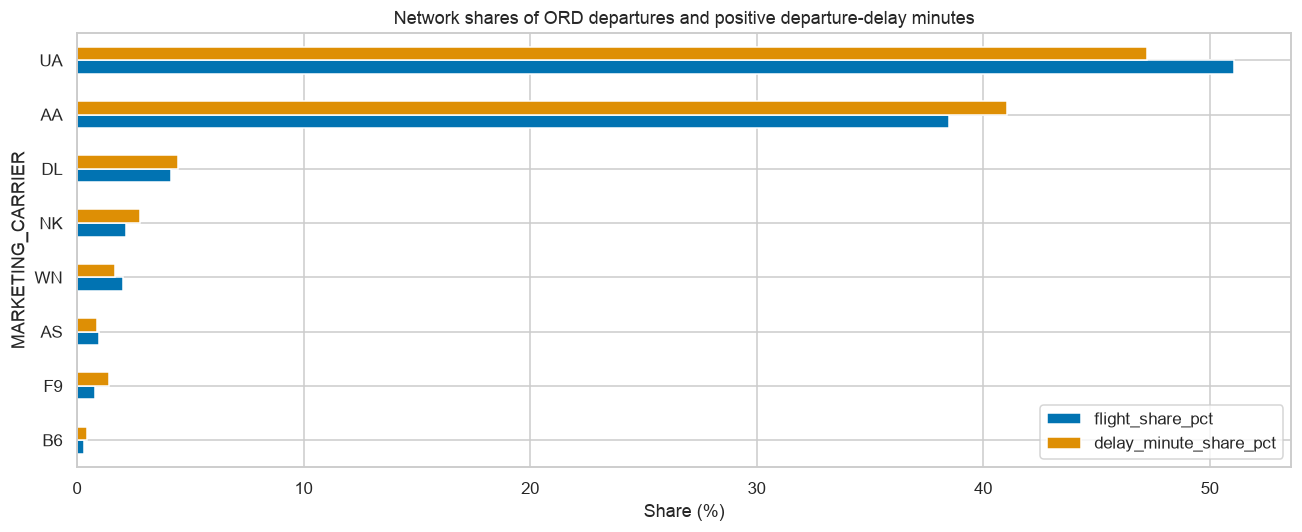

In [13]:
# Count severe delays with a simple True/False column.
flights['SevereDelay'] = flights['DEP_DELAY'] >= 60
grouped = flights.groupby('MARKETING_CARRIER')
burden = pd.DataFrame()
burden['flights'] = grouped['DEP_DELAY'].size()
burden['positive_delay_minutes'] = grouped['PositiveDepDelay'].sum()
burden['severe_delays'] = grouped['SevereDelay'].sum()
burden['flight_share_pct'] = burden['flights'] / burden['flights'].sum() * 100
burden['delay_minute_share_pct'] = burden['positive_delay_minutes'] / burden['positive_delay_minutes'].sum() * 100
burden['severe_delay_pct'] = burden['severe_delays'] / burden['flights'] * 100
display(burden.sort_values('positive_delay_minutes', ascending=False))
burden_plot = burden[['flight_share_pct', 'delay_minute_share_pct']]
burden_plot = burden_plot.sort_values('flight_share_pct')
burden_plot.plot.barh(title='Network shares of ORD departures and positive departure-delay minutes')
plt.xlabel('Share (%)')
plt.tight_layout()
plt.show()


### Taxi-out

Taxi-out runs from gate departure to takeoff. It is a separate measure from departure delay.

,taxi-out minutes
count,1109123.0
mean,24.92
std,12.67
min,1.0
50%,22.0
90%,39.0
95%,48.0
99%,73.0
max,214.0


,count,mean,median
ScheduledDepHour,,,
0,364,19.8,18.0
5,10128,16.58,15.0
6,28418,18.7,16.0
7,76716,23.96,21.0
8,99884,25.18,22.0
9,84566,27.09,24.0
10,84330,24.27,21.0
11,46003,22.92,20.0
12,55215,22.49,20.0


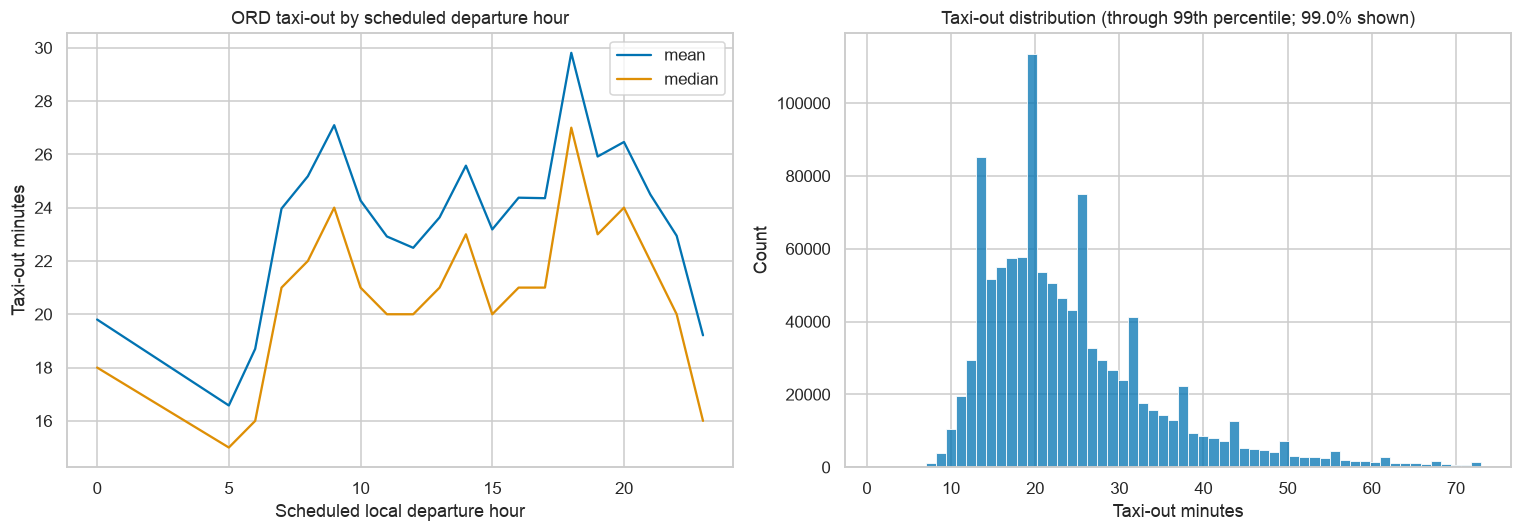

In [14]:
# The cleaned input already requires nonnegative taxi-out minutes.
taxi_valid = flights
display(taxi_valid['TAXI_OUT'].describe(percentiles=[.5,.9,.95,.99]).to_frame('taxi-out minutes'))
grouped = taxi_valid.groupby('ScheduledDepHour')['TAXI_OUT']
taxi = pd.DataFrame()
taxi['count'] = grouped.count()
taxi['mean'] = grouped.mean()
taxi['median'] = grouped.median()
display(taxi)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
taxi[['mean','median']].plot(ax=axes[0], title='ORD taxi-out by scheduled departure hour')
axes[0].set(xlabel='Scheduled local departure hour', ylabel='Taxi-out minutes')
taxi_cutoff = taxi_valid['TAXI_OUT'].quantile(0.99)
central = taxi_valid['TAXI_OUT'] <= taxi_cutoff
sns.histplot(taxi_valid.loc[central, 'TAXI_OUT'], bins=60, ax=axes[1])
axes[1].set(title=f'Taxi-out distribution (through 99th percentile; {central.mean():.1%} shown)', xlabel='Taxi-out minutes')
plt.tight_layout()
plt.show()


## Reported delay reasons

The [BTS dictionary](https://www.transtats.bts.gov/Fields.asp?gnoyr_VQ=FGK) and [Form 1 layout](https://esubmit.rita.dot.gov/On-Time-Form1.aspx) support the five cause labels: carrier, weather, NAS, security, and late aircraft.

These minutes explain **arrival delay on ORD-origin flights**. Use late arrivals with complete, nonnegative, positive cause reports that sum to arrival delay. One flight can have several causes.

Cause coverage among recorded late arrivals: 100.00%


,flights
Eligible ORD departures,1109123
Recorded arrivals delayed ≥15 min,276548
Late arrivals with validated positive causes,276548
Late arrivals excluded from cause summary,0
Nonzero cause sums differing from arrival delay,0


,reported_minutes,flights_with_positive_minutes,share_of_reported_minutes_pct,mean_minutes_when_positive
LATE_AIRCRAFT_DELAY,8676293.0,129025,41.87,67.25
CARRIER_DELAY,6312749.0,145622,30.47,43.35
NAS_DELAY,4036693.0,145762,19.48,27.69
WEATHER_DELAY,1680180.0,24803,8.11,67.74
SECURITY_DELAY,14418.0,519,0.07,27.78


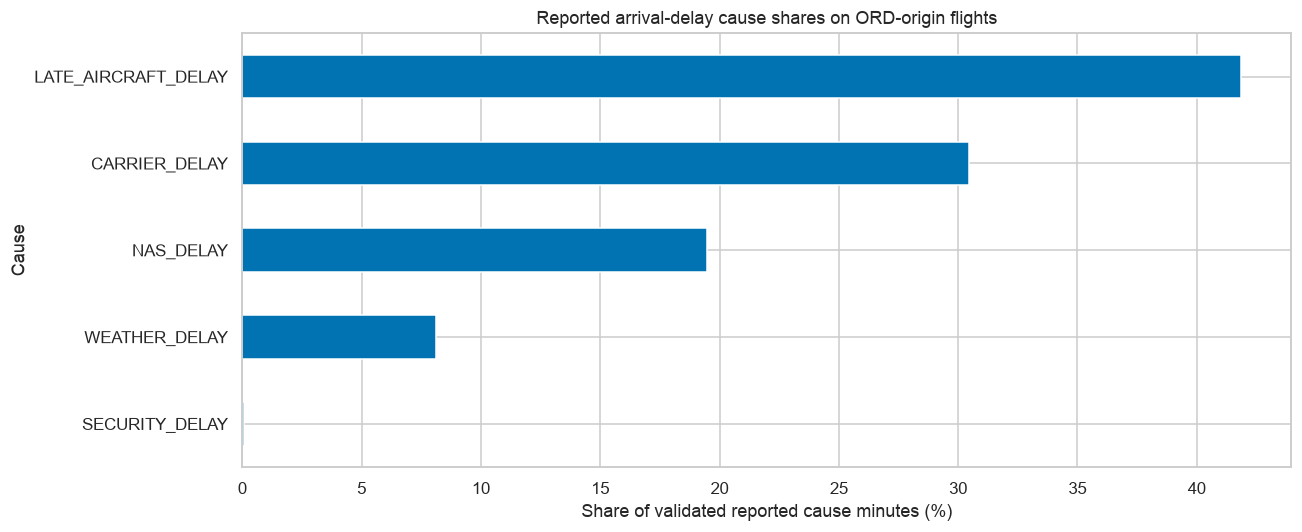

In [15]:
cause_columns = ['CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']
cause_total = flights[cause_columns].sum(axis=1, min_count=len(cause_columns))
# A cause report is useful here only for a recorded late arrival.
late_arrival = (flights['ARR_DELAY'] >= 15).fillna(False)
# axis=1 checks across columns within each flight.
no_missing_causes = flights[cause_columns].notna().all(axis=1)
no_negative_causes = (flights[cause_columns] >= 0).all(axis=1)
complete = no_missing_causes & no_negative_causes
reconciled = (cause_total == flights['ARR_DELAY']).fillna(False)
reported_causes = late_arrival & complete & (cause_total > 0).fillna(False) & reconciled
cause_flights = flights.loc[reported_causes].copy()
coverage = pd.Series({
    'Eligible ORD departures': len(flights),
    'Recorded arrivals delayed ≥15 min': int(late_arrival.sum()),
    'Late arrivals with validated positive causes': len(cause_flights),
    'Late arrivals excluded from cause summary': int((late_arrival & ~reported_causes).sum()),
    'Nonzero cause sums differing from arrival delay': int(((cause_total > 0).fillna(False) & ~reconciled).sum())}, name='flights')
display(coverage.to_frame())
print(f'Cause coverage among recorded late arrivals: {reported_causes.sum() / late_arrival.sum():.2%}')
assert len(cause_flights) > 0
assert cause_flights[cause_columns].sum(axis=1).eq(cause_flights['ARR_DELAY']).all()
reason_summary = pd.DataFrame()
reason_summary['reported_minutes'] = cause_flights[cause_columns].sum()
positive_cause = cause_flights[cause_columns] > 0
reason_summary['flights_with_positive_minutes'] = positive_cause.sum()
reason_summary['share_of_reported_minutes_pct'] = reason_summary['reported_minutes'] / reason_summary['reported_minutes'].sum() * 100
reason_summary['mean_minutes_when_positive'] = reason_summary['reported_minutes'] / reason_summary['flights_with_positive_minutes']
reason_summary = reason_summary.sort_values('reported_minutes', ascending=False)
display(reason_summary)
reason_summary['share_of_reported_minutes_pct'].sort_values().plot.barh(title='Reported arrival-delay cause shares on ORD-origin flights')
plt.xlabel('Share of validated reported cause minutes (%)')
plt.ylabel('Cause')
plt.tight_layout()
plt.show()


### Cause mix over time

Monthly totals show reported delay minutes; percentage shares show how the mix changes. The 2026 series stops in May.

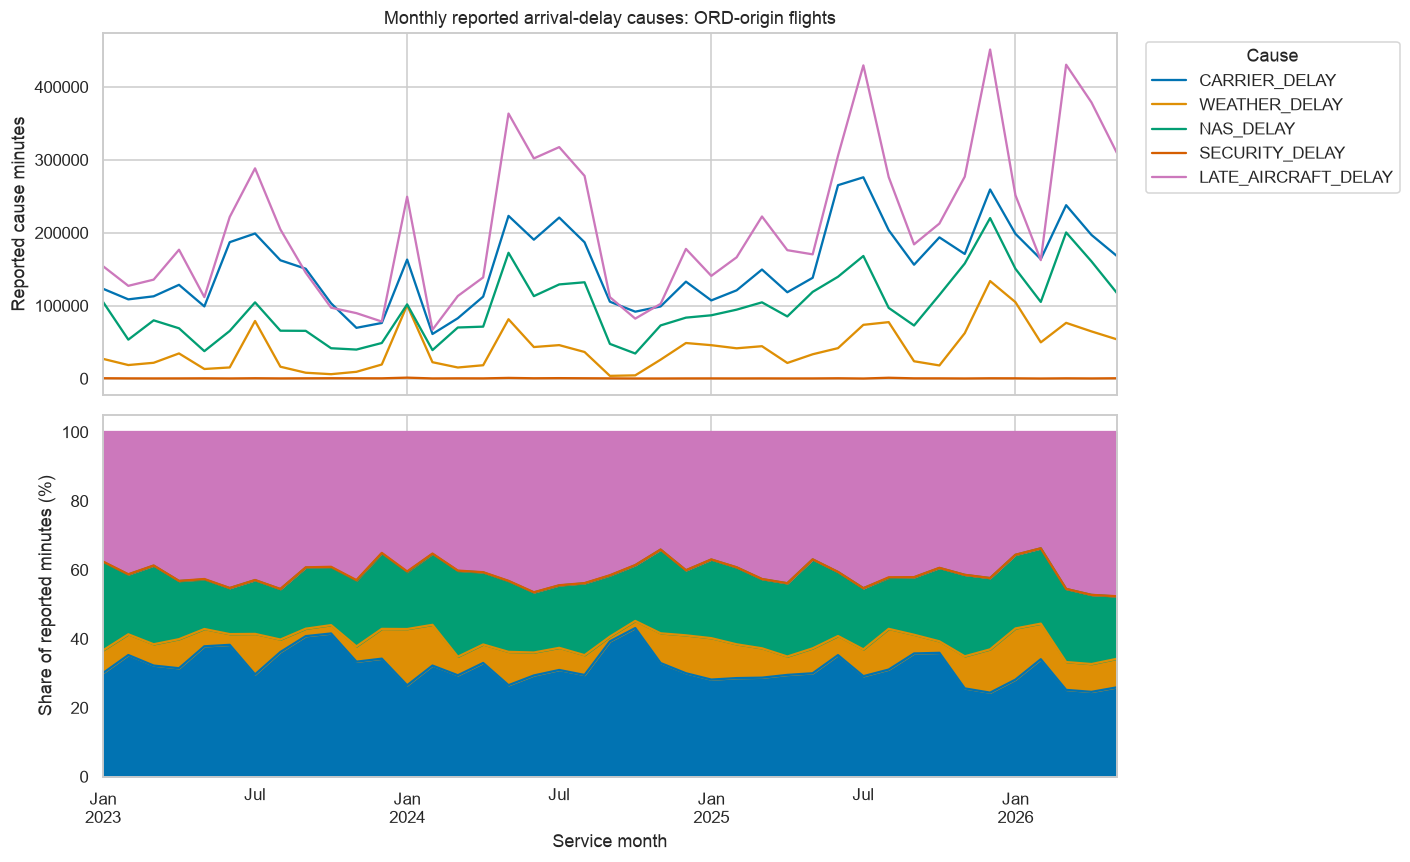

In [16]:
monthly_causes = cause_flights.groupby('MonthStart')[cause_columns].sum()
# Divide each cause by that month's total to get within-month shares.
monthly_totals = monthly_causes.sum(axis=1)
monthly_shares = monthly_causes.copy()
for cause in cause_columns:
    monthly_shares[cause] = monthly_causes[cause] / monthly_totals * 100
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
monthly_causes.plot(ax=axes[0], title='Monthly reported arrival-delay causes: ORD-origin flights')
axes[0].set_ylabel('Reported cause minutes')
monthly_shares.plot.area(ax=axes[1], stacked=True)
axes[1].set(ylabel='Share of reported minutes (%)', xlabel='Service month')
axes[0].legend(title='Cause', bbox_to_anchor=(1.02, 1))
axes[1].legend().remove()
plt.tight_layout()
plt.show()


## Findings

These summaries are calculated from the tables above.

In [17]:
busy_hour = hourly.loc[hourly['flights'].ge(1000)]['delayed15_pct'].idxmax()
worst_month = monthly_dep['delayed15_pct'].idxmax()
largest_network = carrier_dep['flights'].idxmax()
top_route = route_rank.index[0]
findings = [
    f"Coverage: {flights.Date.min():%Y-%m-%d} to {flights.Date.max():%Y-%m-%d}; {len(flights):,} cleaned eligible departures.",
    f"Eligible departure observations: {len(flights):,} from the cleaning notebook; no additional row exclusions.",
    f"Departure delay: mean {flights.DEP_DELAY.mean():.1f} min, median {flights.DEP_DELAY.median():.1f} min, 99th percentile {flights.DEP_DELAY.quantile(.99):.1f} min; {flights.DepDelayed15.mean():.1%} delayed ≥15 min.",
    f"Highest departure-delay rate among hours with ≥1,000 observations: {int(busy_hour):02d}:00 ({hourly.loc[busy_hour, 'delayed15_pct']:.1f}%).",
    f"Highest observed monthly departure-delay rate: {worst_month:%Y-%m} ({monthly_dep.loc[worst_month, 'delayed15_pct']:.1f}%).",
    f"Largest marketing network by eligible volume: {largest_network} ({int(carrier_dep.loc[largest_network, 'flights']):,} flights).",
    f"Highest mean departure delay among destinations with ≥{MIN_ROUTE_FLIGHTS:,} flights: {top_route} ({route_rank.loc[top_route, 'mean_minutes']:.1f} min).",
]
for finding in findings:
    print('•', finding)


• Coverage: 2023-01-01 to 2026-05-31; 1,109,123 cleaned eligible departures.
• Eligible departure observations: 1,109,123 from the cleaning notebook; no additional row exclusions.
• Departure delay: mean 16.1 min, median -2.0 min, 99th percentile 233.0 min; 23.0% delayed ≥15 min.
• Highest departure-delay rate among hours with ≥1,000 observations: 22:00 (37.8%).
• Highest observed monthly departure-delay rate: 2025-12 (35.6%).
• Largest marketing network by eligible volume: UA (566,257 flights).
• Highest mean departure delay among destinations with ≥1,000 flights: JST (38.7 min).


### What to keep in mind

- 2026 covers January–May only.
- Some numbered source fields and schedule differences still need investigation.
- Network and route comparisons include differences in schedules and traffic mix.
- Cause minutes describe arrival delay; taxi-out is measured separately from departure delay.
- Before the prediction project, check which fields are available at prediction time.

## The findings in plain English

Departure means leaving the gate. Taxi-out is the time from leaving the gate to takeoff. Here, “delayed” means at least 15 minutes late.

In [18]:
from IPython.display import Markdown

# Reuse the full-data summaries above; no additional sampling or filtering.
delay_pct = flights['DepDelayed15'].mean() * 100
median_delay = flights['DEP_DELAY'].median()
mean_delay = flights['DEP_DELAY'].mean()
p99_delay = flights['DEP_DELAY'].quantile(.99)
weekday_low = weekday['delayed15_pct'].idxmin()
weekday_high = weekday['delayed15_pct'].idxmax()
cause_shares = reason_summary['share_of_reported_minutes_pct']

reader_findings = f"""
We looked at **{len(flights):,} eligible departures from Chicago O’Hare**, from **{flights['Date'].min():%B %d, %Y} to {flights['Date'].max():%B %d, %Y}**.

1. **About {delay_pct:.0f} out of every 100 flights left at least 15 minutes late.** The other {100-delay_pct:.0f} left early, on schedule, or less than 15 minutes late. Canceled flights are outside this comparison.

2. **The middle flight actually left {abs(median_delay):.0f} minutes {'early' if median_delay < 0 else 'late'}.** Yet the average was {mean_delay:.1f} minutes late. A relatively small number of very long delays pull the average upward—so the average does not describe everyone’s experience.

3. **Early departures had a lower delay rate than late-evening departures.** Flights scheduled between 6:00 and 6:59 a.m. were delayed {hourly.loc[6, 'delayed15_pct']:.1f}% of the time, compared with {hourly.loc[22, 'delayed15_pct']:.1f}% between 10:00 and 10:59 p.m. That is roughly 1 in 10 versus nearly 4 in 10. 

4. **Some waits were longer than a movie.** The longest-delayed 1% of eligible departures were roughly {p99_delay / 60:.1f} hours late or more. Those flights stay in the analysis; they were not deleted just for being unusually late.

5. **The weekday made a difference in this sample.** {weekday_low} had the lowest rate of departures delayed 15+ minutes ({weekday.loc[weekday_low, 'delayed15_pct']:.1f}%), while {weekday_high} had the highest ({weekday.loc[weekday_high, 'delayed15_pct']:.1f}%). Different routes and schedules may contribute to that gap.

6. **Leaving the gate is not the end of the ground wait.** The median taxi-out time was {flights['TAXI_OUT'].median():.0f} minutes. This is a separate part of the trip, after gate departure and before takeoff; it is not an extra {flights['TAXI_OUT'].median():.0f} minutes of measured departure delay.

7. **A late incoming plane was the largest reported delay reason.** It accounted for {cause_shares.loc['LATE_AIRCRAFT_DELAY']:.1f}% of the reported cause minutes. Airline-related issues accounted for {cause_shares.loc['CARRIER_DELAY']:.1f}%, the National Aviation System—such as air-traffic and airport constraints—for {cause_shares.loc['NAS_DELAY']:.1f}%, weather for {cause_shares.loc['WEATHER_DELAY']:.1f}%, and security for {cause_shares.loc['SECURITY_DELAY']:.2f}%. These are shares of reported **arrival-delay minutes on flights that departed ORD**, not percentages of flights or a breakdown of departure delay. One flight can have several reasons.

2026 covers January–May only. The five cause labels come from the BTS schema reconstruction in the cleaning notebook.
"""
display(Markdown(reader_findings))



We looked at **1,109,123 eligible departures from Chicago O’Hare**, from **January 01, 2023 to May 31, 2026**.

1. **About 23 out of every 100 flights left at least 15 minutes late.** The other 77 left early, on schedule, or less than 15 minutes late. Canceled flights are outside this comparison.

2. **The middle flight actually left 2 minutes early.** Yet the average was 16.1 minutes late. A relatively small number of very long delays pull the average upward—so the average does not describe everyone’s experience.

3. **Early departures had a lower delay rate than late-evening departures.** Flights scheduled between 6:00 and 6:59 a.m. were delayed 9.9% of the time, compared with 37.8% between 10:00 and 10:59 p.m. That is roughly 1 in 10 versus nearly 4 in 10. 

4. **Some waits were longer than a movie.** The longest-delayed 1% of eligible departures were roughly 3.9 hours late or more. Those flights stay in the analysis; they were not deleted just for being unusually late.

5. **The weekday made a difference in this sample.** Tuesday had the lowest rate of departures delayed 15+ minutes (20.2%), while Sunday had the highest (25.4%). Different routes and schedules may contribute to that gap.

6. **Leaving the gate is not the end of the ground wait.** The median taxi-out time was 22 minutes. This is a separate part of the trip, after gate departure and before takeoff; it is not an extra 22 minutes of measured departure delay.

7. **A late incoming plane was the largest reported delay reason.** It accounted for 41.9% of the reported cause minutes. Airline-related issues accounted for 30.5%, the National Aviation System—such as air-traffic and airport constraints—for 19.5%, weather for 8.1%, and security for 0.07%. These are shares of reported **arrival-delay minutes on flights that departed ORD**, not percentages of flights or a breakdown of departure delay. One flight can have several reasons.

2026 covers January–May only. The five cause labels come from the BTS schema reconstruction in the cleaning notebook.
